# Match-Day Nutrition with QAOA
**Qompute 2026, Track 2: Optimizing for People**

How many servings of 8 dining-hall foods should a squash player eat on match day to hit nutrient targets, while eating a fixed number of portions?

The problem is written as a cost function, converted to a QUBO and an Ising cost Hamiltonian, solved with QAOA in Qiskit, and checked against brute force over all 65,536 possible menus. The analysis then changes the weights and the penalty to show how those choices decide what counts as the "optimal" plate.

**Pipeline:** data → cost function → brute force → QUBO/Ising → QAOA → compare → profiles and sweeps

*Nutrition values are from USDA FoodData Central (FDC IDs in the data cell). Targets are invented for demonstration only. This is not dietary advice.*

The QAOA loop follows the pattern of `Track2_challenge_2_tutorial.ipynb` (B. Tirado, BasQ Qiskit Fall Fest 2026, CC BY 4.0).

In [1]:
import itertools, time
import numpy as np
import matplotlib.pyplot as plt
from scipy.optimize import minimize

from qiskit import transpile
from qiskit.circuit.library import QAOAAnsatz
from qiskit.quantum_info import Statevector
from qiskit.primitives import StatevectorEstimator, StatevectorSampler
from qiskit_optimization import QuadraticProgram
from qiskit_optimization.converters import QuadraticProgramToQubo

rng = np.random.default_rng(7)   # fixed seed, so the run is reproducible

## 1. Data: foods and nutrients per serving
Per-serving values come from USDA FoodData Central (SR Legacy) entries, scaled to the serving size shown.

| Food | Serving | Source |
|---|---|---|
| Scrambled eggs | 100 g | FDC 172187 |
| Oatmeal, cooked in water | 175 g | FDC 173905 |
| Chicken thigh, roasted | 150 g | FDC 172388 |
| White rice, cooked | 150 g | FDC 168878 |
| Vegetables (broccoli, boiled) | 100 g | USDA SR Legacy, broccoli boiled without salt |
| Banana | 109 g edible | FDC 173944 |
| Peanut butter | 32 g | FDC 174266 |
| Pizza, pepperoni | 1 slice, 108.5 g | FDC 173295 |

In [2]:
foods = ["eggs", "oatmeal", "chicken", "rice", "vegetables", "banana", "peanut_butter", "pizza"]
nutrients = ["kcal", "protein_g", "carbs_g", "fat_g", "potassium_mg", "sodium_mg"]

# rows = foods, columns = nutrients (per serving)
A = np.array([
    #  kcal  prot  carbs  fat    K     Na
    [149, 10.0,  1.6, 11.0, 132, 145],   # eggs, 100 g
    [124,  4.4, 21.0,  2.7, 122,   7],   # oatmeal, 175 g
    [268, 37.1,  0.0, 12.2, 406, 159],   # chicken thigh, 150 g
    [195,  4.0, 42.3,  0.4,  52,   2],   # white rice, 150 g
    [ 35,  2.9,  7.2,  0.4, 181,  13],   # broccoli, 100 g
    [ 97,  1.2, 24.9,  0.4, 390,   1],   # banana, 109 g
    [191,  7.1,  7.1, 16.4, 179, 136],   # peanut butter, 32 g
    [306, 12.7, 34.7, 12.9, 212, 743],   # pizza, 1 slice
])

# Assumed match-day targets (invented, see README). Macros check: 4*150 + 4*320 + 9*80 = 2600 kcal
targets = {"kcal": 2600, "protein_g": 150, "carbs_g": 320, "fat_g": 80, "potassium_mg": 3000}
SODIUM_REF = 2300        # mg; sodium is treated as "less is better", scaled by this reference
MAX_SERVINGS = 3         # each food 0..3 servings -> 2 qubits per food
TOTAL_SERVINGS = 14      # constraint: exactly this many portions across the day

T = np.array([targets[k] for k in nutrients[:5]], dtype=float)
print("Macro check:", 4*targets["protein_g"] + 4*targets["carbs_g"] + 9*targets["fat_g"], "kcal")

Macro check: 2600 kcal


## 2. The cost function
Let $n_i \in \{0,1,2,3\}$ be the servings of food $i$, and $a_{ki}$ the amount of nutrient $k$ in one serving.

$$
C(n) = \sum_{k \in \text{targets}} w_k \left(\frac{\sum_i a_{ki} n_i - T_k}{T_k}\right)^2 \;+\; w_{\text{Na}}\,\frac{\sum_i a_{\text{Na},i}\, n_i}{2300} \;+\; \lambda\left(\sum_i n_i - N\right)^2
$$

- **Squared relative deviation:** missing a target in either direction is penalized, and dividing by $T_k$ makes grams and milligrams comparable.
- **Weights $w_k$:** how much each goal matters. *This is a value judgment.*
- **Sodium term:** linear, so less sodium is always better. A hard cap would need extra slack qubits.
- **Constraint $\sum_i n_i = N$:** a fixed number of portions, enforced as a penalty with strength $\lambda$. *Choosing $\lambda$ is also a value judgment.*

**Binary encoding:** $n_i = x_{i,0} + 2x_{i,1}$, which gives 8 foods × 2 bits = **16 qubits**. Squaring the sums creates pair terms between almost every pair of bits, which become ZZ interactions in the Hamiltonian.

In [3]:
# Three "stakeholder" profiles: weights for (kcal, protein, carbs, fat, potassium), sodium weight
profiles = {
    "macros_only":  {"w": np.array([1, 1, 1, 1, 1.0]), "w_na": 0.0},  # ignores sodium entirely
    "performance":  {"w": np.array([1, 2, 2, 1, 0.5]), "w_na": 0.1},  # protein + carbs matter most
    "low_sodium":   {"w": np.array([1, 1, 1, 1, 1.0]), "w_na": 1.0},  # heart-health framing
}

def menu_cost(n, w, w_na, lam=0.0, N=TOTAL_SERVINGS):
    # Cost of one or many menus. n has shape (..., 8)
    tot = n @ A
    dev = (tot[..., :5] - T) / T
    c = (w * dev**2).sum(-1) + w_na * tot[..., 5] / SODIUM_REF
    return c + lam * (n.sum(-1) - N) ** 2

## 3. Classical brute force: the ground truth
There are $4^8 = 65{,}536$ menus. A laptop scores all of them in milliseconds, which gives the exact answer to judge QAOA against.

In [4]:
ALL_MENUS = np.array(list(itertools.product(range(MAX_SERVINGS + 1), repeat=len(foods))))

def brute_force(w, w_na, constrained=True):
    if constrained:
        feasible = ALL_MENUS[ALL_MENUS.sum(1) == TOTAL_SERVINGS]
    else:
        feasible = ALL_MENUS
    c = menu_cost(feasible, w, w_na)
    order = np.argsort(c)
    return feasible[order], c[order]

def show_menu(n, label=""):
    tot = n @ A
    parts = [f"{foods[i]}x{n[i]}" for i in range(len(foods)) if n[i] > 0]
    print(f"{label:<14}", ", ".join(parts))
    print(f"{'':<14} kcal {tot[0]:.0f}/{T[0]:.0f} | P {tot[1]:.0f}/{T[1]:.0f} g | C {tot[2]:.0f}/{T[2]:.0f} g | "
          f"F {tot[3]:.0f}/{T[3]:.0f} g | K {tot[4]:.0f}/{T[4]:.0f} mg | Na {tot[5]:.0f} mg | servings {n.sum()}")

t0 = time.time()
bf = {}
for name, p in profiles.items():
    menus, costs = brute_force(p["w"], p["w_na"])
    bf[name] = (menus, costs)
    show_menu(menus[0], name)
print(f"\nBrute force for 3 profiles took {time.time()-t0:.2f} s; feasible menus with exactly "
      f"{TOTAL_SERVINGS} servings: {len(bf['performance'][0])}")

macros_only    eggsx1, oatmealx1, chickenx2, ricex3, vegetablesx2, bananax2, pizzax3
               kcal 2576/2600 | P 147/150 g | C 318/320 g | F 80/80 g | K 3000/3000 mg | Na 2733 mg | servings 14
performance    oatmealx3, chickenx3, ricex3, bananax3, peanut_butterx2
               kcal 2434/2600 | P 154/150 g | C 279/320 g | F 80/80 g | K 3268/3000 mg | Na 779 mg | servings 14
low_sodium     oatmealx3, chickenx3, ricex3, vegetablesx1, bananax3, peanut_butterx1
               kcal 2278/2600 | P 150/150 g | C 279/320 g | F 64/80 g | K 3270/3000 mg | Na 656 mg | servings 14

Brute force for 3 profiles took 0.02 s; feasible menus with exactly 14 servings: 6728


## 4. Build the QuadraticProgram → QUBO → Ising Hamiltonian
Qiskit Optimization handles the integer-to-binary encoding and turns the equality constraint into the $\lambda$ penalty.

Expanding $(\sum_i a_i n_i - T)^2$ gives a constant, linear terms, and pair terms. We build exactly those coefficients and pass them to `QuadraticProgram`.

In [5]:
def build_qp(w, w_na):
    qp = QuadraticProgram("match_day_nutrition")
    for f in foods:
        qp.integer_var(lowerbound=0, upperbound=MAX_SERVINGS, name=f)

    # Expand sum_k w_k ((a_k . n - T_k)/T_k)^2  =  n^T Q n + L . n + const
    Q = np.zeros((8, 8)); L = np.zeros(8); const = 0.0
    for k in range(5):
        a = A[:, k] / T[k]                     # relative contribution of one serving
        Q += w[k] * np.outer(a, a)
        L += -2 * w[k] * a                     # from the cross term -2 * (a.n) * 1
        const += w[k]                          # from (-1)^2
    L += w_na * A[:, 5] / SODIUM_REF           # linear sodium penalty

    quad = {}
    for i in range(8):
        for j in range(i, 8):
            coeff = Q[i, i] if i == j else 2 * Q[i, j]
            quad[(foods[i], foods[j])] = coeff
    qp.minimize(constant=const, linear=dict(zip(foods, L)), quadratic=quad)
    qp.linear_constraint(linear={f: 1 for f in foods}, sense="==", rhs=TOTAL_SERVINGS, name="portions")
    return qp

name = "performance"
p = profiles[name]
qp = build_qp(p["w"], p["w_na"])

# Sanity check: the QuadraticProgram objective equals our numpy cost function
test = ALL_MENUS[rng.integers(len(ALL_MENUS), size=5)]
for n in test:
    assert np.isclose(qp.objective.evaluate(n), menu_cost(n, p["w"], p["w_na"]))
print("QuadraticProgram objective matches menu_cost on random menus")

QuadraticProgram objective matches menu_cost on random menus


In [6]:
LAMBDA = 1.0   # penalty strength for breaking the "exactly N servings" rule

def to_hamiltonian(qp, lam=LAMBDA):
    conv = QuadraticProgramToQubo(penalty=lam)
    qubo = conv.convert(qp)
    op, offset = qubo.to_ising()
    return conv, qubo, op, offset

conv, qubo, cost_op, offset = to_hamiltonian(qp)
print("Qubits:", cost_op.num_qubits)
print("Pauli terms:", len(cost_op), "(Z terms + ZZ terms)")
print("Binary variables:", [v.name for v in qubo.variables][:6], "...")

Qubits: 16
Pauli terms: 136 (Z terms + ZZ terms)
Binary variables: ['eggs@0', 'eggs@1', 'oatmeal@0', 'oatmeal@1', 'chicken@0', 'chicken@1'] ...


**Bit-to-qubit mapping.** Qubit $q$ corresponds to `qubo.variables[q]`. Computational basis state index $b$ has qubit $q$ equal to `(b >> q) & 1` (Qiskit is little-endian). `conv.interpret(x)` turns the 16 bits back into 8 serving counts.

Before trusting QAOA, check that the Hamiltonian's lowest-energy basis state equals the brute-force optimum.

In [7]:
NQ = cost_op.num_qubits
idx = np.arange(2**NQ)
BITS = ((idx[:, None] >> np.arange(NQ)) & 1).astype(float)          # all 65,536 bitstrings

def bits_to_menu(bits):
    return np.array(conv.interpret(bits), dtype=int)

# Energy of every basis state, straight from the Pauli operator (diagonal: only I/Z terms)
def diagonal_energies(op):
    E = np.zeros(2**op.num_qubits)
    for pauli, coeff in zip(op.paulis, op.coeffs):
        zmask = pauli.z
        sign = np.prod(np.where(BITS[:, zmask] == 1, -1.0, 1.0), axis=1) if zmask.any() else 1.0
        E += coeff.real * sign
    return E

E = diagonal_energies(cost_op) + offset
ground = int(np.argmin(E))
menu_h = bits_to_menu(BITS[ground])
show_menu(menu_h, "Hamiltonian GS")
show_menu(bf[name][0][0], "Brute force")
print("Match:", np.array_equal(menu_h, bf[name][0][0]))

Hamiltonian GS oatmealx3, chickenx3, ricex3, bananax3, peanut_butterx2
               kcal 2434/2600 | P 154/150 g | C 279/320 g | F 80/80 g | K 3268/3000 mg | Na 779 mg | servings 14
Brute force    oatmealx3, chickenx3, ricex3, bananax3, peanut_butterx2
               kcal 2434/2600 | P 154/150 g | C 279/320 g | F 80/80 g | K 3268/3000 mg | Na 779 mg | servings 14
Match: True


## 5. QAOA
The circuit alternates a cost layer $e^{-i\gamma H_C}$ and a mixer $e^{-i\beta \sum X}$, repeated $p$ times. COBYLA tunes $(\gamma, \beta)$ to minimize $\langle H_C \rangle$.

The Hamiltonian is divided by its largest coefficient so that sensible angles are of order 1. This does not change which state has the lowest energy.

For $p=1$ we first scan a grid of angles, then warm-start deeper circuits from it.

In [8]:
scale = np.max(np.abs(cost_op.coeffs))
H = (cost_op / scale).simplify()
estimator = StatevectorEstimator()

def qaoa_circuit(p):
    # Break the cost/mixer layers into 1- and 2-qubit gates (RZ, RZZ, RX, H).
    # Without this, the simulator tries to build a 65,536 x 65,536 matrix (64 GB) for 16 qubits.
    return transpile(QAOAAnsatz(cost_operator=H, reps=p),
                     basis_gates=["h", "rx", "rz", "rzz"], optimization_level=0)

def make_cost_fn(ansatz):
    history = []
    def f(params):
        val = float(estimator.run([(ansatz, H, params)]).result()[0].data.evs)
        history.append(val)
        return val
    return f, history

# p = 1 grid scan
ans1 = qaoa_circuit(1)
f1, _ = make_cost_fn(ans1)
gammas = np.linspace(0.05, 1.5, 12); betas = np.linspace(0.05, 1.5, 12)
t0 = time.time()
grid = np.array([[f1([b, g]) for b in betas] for g in gammas])   # QAOAAnsatz parameter order: [beta, gamma]
gi, bi = np.unravel_index(np.argmin(grid), grid.shape)
print(f"p=1 grid best <H> = {grid[gi, bi]:.4f} at gamma={gammas[gi]:.2f}, beta={betas[bi]:.2f}  ({time.time()-t0:.1f} s)")
print("Parameter order:", list(ans1.parameters))

p=1 grid best <H> = -0.3674 at gamma=0.18, beta=1.50  (77.1 s)
Parameter order: [ParameterVectorElement(β[0]), ParameterVectorElement(γ[0])]


In [9]:
def run_qaoa(p, init):
    ansatz = qaoa_circuit(p)
    f, hist = make_cost_fn(ansatz)
    res = minimize(f, init, method="COBYLA", options={"maxiter": 150 * p})
    return ansatz, res, hist

def init_params(prev, p):
    # Simple warm start: reuse the previous layers' angles and repeat the last ones
    b, g = list(prev[:len(prev)//2]), list(prev[len(prev)//2:])
    while len(b) < p:
        b.append(b[-1]); g.append(g[-1])
    return np.array(b + g)

results = {}
params = np.array([betas[bi], gammas[gi]])
for p_layers in [1, 2, 3]:
    t0 = time.time()
    x0 = init_params(params, p_layers)
    ansatz, res, hist = run_qaoa(p_layers, x0)
    params = res.x
    sv_probs = Statevector(ansatz.assign_parameters(res.x)).probabilities()
    results[p_layers] = dict(ansatz=ansatz, res=res, hist=hist, probs=sv_probs)
    print(f"p={p_layers}: <H>={res.fun:.4f}, evaluations={res.nfev}, time={time.time()-t0:.1f} s")

p=1: <H>=-2.8582, evaluations=48, time=48.4 s
p=2: <H>=-3.1201, evaluations=300, time=400.7 s
p=3: <H>=-3.1945, evaluations=450, time=807.8 s


## 6. How good is QAOA? Comparison with brute force
For each depth $p$ we compute the exact output distribution, so there is no shot noise, and report:

- **P(optimum):** probability of measuring the brute-force best menu.
- **P(top 1%):** probability of landing in the best 1% of all 65,536 bitstrings.
- **P(feasible):** probability of exactly 14 servings.
- **Expected cost** compared with a uniformly random guess.

In [10]:
order = np.argsort(E)
rank_of = np.empty_like(order); rank_of[order] = np.arange(len(order))
top1 = rank_of < int(0.01 * len(E))      # best 1% of all bitstrings by true cost

In [11]:
# Serving count per bitstring (vectorized). Use conv.interpret on one state to confirm the bit layout first.
var_names = [v.name for v in qubo.variables]
print(var_names[:4])
servings = np.zeros((2**NQ, 8))
for q, vname in enumerate(var_names):
    food, bit = vname.split("@")
    servings[:, foods.index(food)] += BITS[:, q] * (2 ** int(bit))
assert np.array_equal(servings[ground].astype(int), menu_h)
feasible_mask = servings.sum(1) == TOTAL_SERVINGS

uniform = np.full(2**NQ, 1 / 2**NQ)
def summarize(probs, label):
    return dict(label=label,
                p_opt=probs[ground],
                p_top1=probs[top1].sum(),
                p_feas=probs[feasible_mask].sum(),
                exp_cost=(probs * E).sum())

rows = [summarize(uniform, "random guess")] + [summarize(r["probs"], f"QAOA p={k}") for k, r in results.items()]
print(f"{'':<14}{'P(opt)':>10}{'P(top1%)':>10}{'P(feas)':>10}{'E[cost]':>10}")
for r in rows:
    print(f"{r['label']:<14}{r['p_opt']:>10.4f}{r['p_top1']:>10.3f}{r['p_feas']:>10.3f}{r['exp_cost']:>10.3f}")
print(f"\nBrute-force optimum cost: {E[ground]:.4f}")

['eggs@0', 'eggs@1', 'oatmeal@0', 'oatmeal@1']
                  P(opt)  P(top1%)   P(feas)   E[cost]
random guess      0.0000     0.010     0.103    14.988
QAOA p=1          0.0000     0.028     0.283     2.854
QAOA p=2          0.0001     0.037     0.379     1.743
QAOA p=3          0.0001     0.043     0.434     1.427

Brute-force optimum cost: 0.0767


In [12]:
# Sample the best circuit like on hardware (shots) and read off the best menu found
best_p = max(results, key=lambda k: results[k]["probs"][ground])
ans_meas = results[best_p]["ansatz"].copy(); ans_meas.measure_all()
sampler = StatevectorSampler(seed=7)
counts = sampler.run([ans_meas.assign_parameters(results[best_p]["res"].x)], shots=4096).result()[0].data.meas.get_counts()

def bitstring_to_index(s):
    return int(s, 2)      # Qiskit prints qubit 0 on the right, so int(s, 2) gives the basis index

sampled = sorted(counts.items(), key=lambda kv: E[bitstring_to_index(kv[0])])
best_idx = bitstring_to_index(sampled[0][0])
print(f"Depth p={best_p}, 4096 shots, {len(counts)} distinct bitstrings")
show_menu(servings[best_idx].astype(int), "QAOA best")
show_menu(menu_h, "Brute force")
print(f"Rank of QAOA's best sample among all 65,536 states: {rank_of[best_idx] + 1}")
print(f"Times the true optimum was measured: {counts.get(format(ground, f'0{NQ}b'), 0)}")

Depth p=3, 4096 shots, 3715 distinct bitstrings
QAOA best      eggsx1, oatmealx3, chickenx2, ricex3, bananax3, peanut_butterx1, pizzax1
               kcal 2430/2600 | P 133/150 g | C 308/320 g | F 75/80 g | K 3027/3000 mg | Na 1372 mg | servings 14
Brute force    oatmealx3, chickenx3, ricex3, bananax3, peanut_butterx2
               kcal 2434/2600 | P 154/150 g | C 279/320 g | F 80/80 g | K 3268/3000 mg | Na 779 mg | servings 14
Rank of QAOA's best sample among all 65,536 states: 6
Times the true optimum was measured: 0


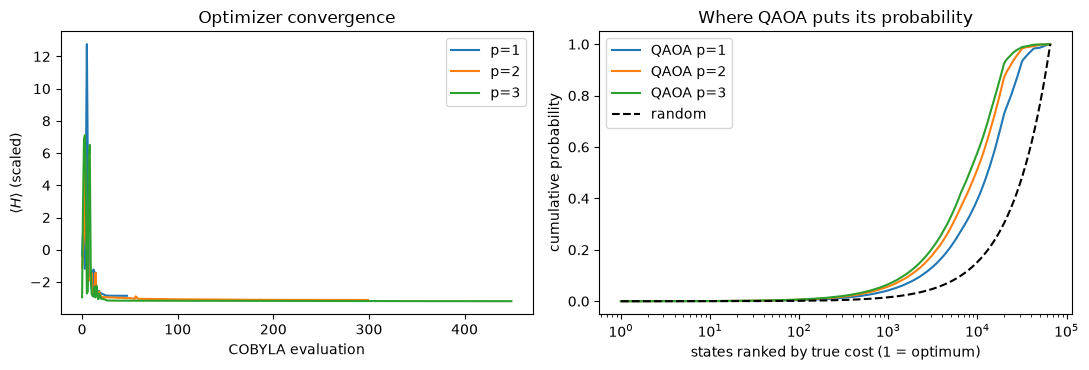

In [13]:
fig, ax = plt.subplots(1, 2, figsize=(11, 3.8))
for k, r in results.items():
    ax[0].plot(r["hist"], label=f"p={k}")
ax[0].set_xlabel("COBYLA evaluation"); ax[0].set_ylabel(r"$\langle H \rangle$ (scaled)"); ax[0].legend()
ax[0].set_title("Optimizer convergence")

ranks = np.arange(1, 2**NQ + 1)
for k, r in results.items():
    ax[1].plot(ranks, np.cumsum(r["probs"][order]), label=f"QAOA p={k}")
ax[1].plot(ranks, ranks / 2**NQ, "k--", label="random")
ax[1].set_xscale("log"); ax[1].set_xlabel("states ranked by true cost (1 = optimum)")
ax[1].set_ylabel("cumulative probability"); ax[1].legend(); ax[1].set_title("Where QAOA puts its probability")
plt.tight_layout(); plt.savefig("qaoa_vs_bruteforce.png", dpi=150); plt.show()

## 7. Whose optimum? Profiles, the pizza test, and the penalty knob
The same foods and data give different "optimal" menus depending on who sets the weights. These sweeps use brute force, because the question is about the objective, not the solver.

In [14]:
print("Optimal menu per profile (exactly 14 servings):\n")
for name_, p_ in profiles.items():
    show_menu(bf[name_][0][0], name_)
    print()

# Regret matrix: if you eat profile i's menu but are judged by profile j's cost, how much worse than j's own optimum?
names = list(profiles)
regret = np.zeros((3, 3))
for i, ni in enumerate(names):
    for j, nj in enumerate(names):
        menu_i = bf[ni][0][0]
        regret[i, j] = menu_cost(menu_i, profiles[nj]["w"], profiles[nj]["w_na"]) - bf[nj][1][0]
print("Regret (rows: menu chosen by, cols: judged by)")
print(f"{'':<14}" + "".join(f"{n:>14}" for n in names))
for i, n in enumerate(names):
    print(f"{n:<14}" + "".join(f"{v:>14.3f}" for v in regret[i]))

Optimal menu per profile (exactly 14 servings):

macros_only    eggsx1, oatmealx1, chickenx2, ricex3, vegetablesx2, bananax2, pizzax3
               kcal 2576/2600 | P 147/150 g | C 318/320 g | F 80/80 g | K 3000/3000 mg | Na 2733 mg | servings 14

performance    oatmealx3, chickenx3, ricex3, bananax3, peanut_butterx2
               kcal 2434/2600 | P 154/150 g | C 279/320 g | F 80/80 g | K 3268/3000 mg | Na 779 mg | servings 14

low_sodium     oatmealx3, chickenx3, ricex3, vegetablesx1, bananax3, peanut_butterx1
               kcal 2278/2600 | P 150/150 g | C 279/320 g | F 64/80 g | K 3270/3000 mg | Na 656 mg | servings 14

Regret (rows: menu chosen by, cols: judged by)
                 macros_only   performance    low_sodium
macros_only            0.000         0.043         0.823
performance            0.029         0.000         0.002
low_sodium             0.080         0.045         0.000


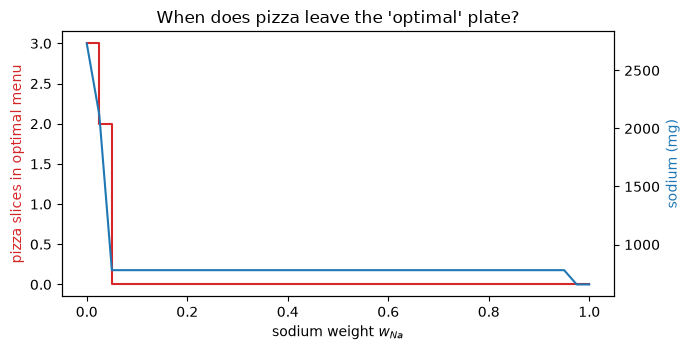

Pizza slices at w_Na=0: 3 | first weight with fewer slices: 0.025


In [15]:
# The pizza test: how does the optimal number of pizza slices change as sodium matters more?
w_na_grid = np.linspace(0, 1.0, 41)
pizza, sodium = [], []
for w_na in w_na_grid:
    menu = brute_force(np.ones(5), w_na)[0][0]
    pizza.append(menu[foods.index("pizza")]); sodium.append((menu @ A)[5])

fig, ax1 = plt.subplots(figsize=(7, 3.6))
ax1.step(w_na_grid, pizza, where="post", color="C3", label="pizza slices")
ax1.set_xlabel("sodium weight $w_{Na}$"); ax1.set_ylabel("pizza slices in optimal menu", color="C3")
ax2 = ax1.twinx(); ax2.plot(w_na_grid, sodium, color="C0"); ax2.set_ylabel("sodium (mg)", color="C0")
ax1.set_title("When does pizza leave the 'optimal' plate?")
plt.tight_layout(); plt.savefig("pizza_sweep.png", dpi=150); plt.show()
flip = w_na_grid[np.argmax(np.array(pizza) < pizza[0])] if min(pizza) < pizza[0] else None
print("Pizza slices at w_Na=0:", pizza[0], "| first weight with fewer slices:", flip)

In [16]:
# The penalty knob: too small a lambda and the "optimal" Hamiltonian state breaks the 14-serving rule
p_ = profiles["performance"]
for lam in [0.0, 0.001, 0.01, 0.05, 0.1, 1.0]:
    best = ALL_MENUS[np.argmin(menu_cost(ALL_MENUS, p_["w"], p_["w_na"], lam=lam))]
    print(f"lambda={lam:<6} servings={best.sum():>2}  feasible={best.sum()==TOTAL_SERVINGS}  menu={best}")

lambda=0.0    servings=16  feasible=False  menu=[3 3 2 3 1 3 0 1]
lambda=0.001  servings=15  feasible=False  menu=[3 3 2 3 0 3 0 1]
lambda=0.01   servings=14  feasible=True  menu=[0 3 3 3 0 3 2 0]
lambda=0.05   servings=14  feasible=True  menu=[0 3 3 3 0 3 2 0]
lambda=0.1    servings=14  feasible=True  menu=[0 3 3 3 0 3 2 0]
lambda=1.0    servings=14  feasible=True  menu=[0 3 3 3 0 3 2 0]


## 8. Takeaways (fill in from your results)
- **Correctness:** the Hamiltonian's ground state matches the brute-force optimum.
- **QAOA performance:** compare P(optimum) and P(top 1%) against random guessing as $p$ grows. With 16 densely coupled qubits at low depth, expect QAOA to concentrate probability on good menus without reliably returning the single best one.
- **Classical vs quantum:** brute force solves this instance in milliseconds. This project uses QAOA as a test case for encoding a constrained human objective, not as a claimed speedup.
- **Whose optimum:** the profiles, regret matrix, and pizza sweep show that the "optimal" menu is set by the weights. Someone chose those weights.
- **What's left out:** taste, cost, culture, allergies, meal timing around the match, digestion, and access to dining halls.